#### Importing Libraries

In [1]:
# Importing libraries for model evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Configuring display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

# Defining project directories

processed_dir = Path("../data/processed")
trained_models_dir = Path("../models/trained")
preprocessed_models_dir = Path("../models/preprocessed")
figures_dir = Path("../reports/figures")

figures_dir.mkdir(parents=True, exist_ok=True)

print("Libraries Imported Successfully.")
print("Evaluation Directories Configured Successfully.")

Libraries Imported Successfully.
Evaluation Directories Configured Successfully.


#### 1. Loading Evaluation Data

In [2]:
# Loading processed test features and encoded target labels

X_test = pd.read_parquet(
    processed_dir / "X_test_processed.parquet"
)

y_test = pd.read_parquet(
    processed_dir / "y_test_encoded.parquet"
).squeeze()

# Loading the fitted label encoder

label_encoder = joblib.load(
    preprocessed_models_dir / "label_encoder.joblib"
)

# Loading cross-validation model comparison

model_comparison = pd.read_csv(
    processed_dir / "model_comparison.csv"
)

# Verifying dataset dimensions

print("Test Features Shape:", X_test.shape)
print("Test Target Shape:", y_test.shape)

print("\nSeverity Class Mapping:")

for class_index, class_name in enumerate(label_encoder.classes_):
    print(f"{class_index}: {class_name}")

print("\nTest Class Distribution:")
display(
    pd.Series(
        label_encoder.inverse_transform(y_test.to_numpy().ravel())
    ).value_counts()
)

print("\nModel Comparison Records:", len(model_comparison))

print("\nMissing Values in Test Features:", X_test.isna().sum().sum())
print("Infinite Values in Test Features:", np.isinf(X_test.to_numpy()).sum())

Test Features Shape: (200, 13)
Test Target Shape: (200,)

Severity Class Mapping:
0: Critical
1: Minor
2: Moderate

Test Class Distribution:


Minor       72
Critical    66
Moderate    62
Name: count, dtype: int64


Model Comparison Records: 19

Missing Values in Test Features: 0
Infinite Values in Test Features: 0


#### Observations on Data Validation

- The model comparison dataset contains **19 trained model configurations**, confirming that all development experiments are represented.
- The processed test features contain **no missing or infinite values**, supporting reliable model evaluation.

#### 2. Loading Trained Models

In [3]:
# Identifying and loading saved classification models

model_files = sorted(trained_models_dir.glob("*.joblib"))

trained_models = {}
loading_errors = {}

for model_path in model_files:
    try:
        trained_models[model_path.stem] = joblib.load(model_path)
    except Exception as error:
        loading_errors[model_path.stem] = str(error)

# Summarizing loaded model artifacts

print("Saved Model Files Found:", len(model_files))
print("Models Loaded Successfully:", len(trained_models))
print("Loading Errors:", len(loading_errors))

print("\nLoaded Models:")

display(
    pd.DataFrame({
        "Model File": list(trained_models.keys()),
        "Algorithm": [
            type(model).__name__
            for model in trained_models.values()
        ]
    })
)

if loading_errors:
    print("\nModel Loading Errors:")
    display(pd.DataFrame(
        loading_errors.items(),
        columns=["Model", "Error"]
    ))

Saved Model Files Found: 19
Models Loaded Successfully: 19
Loading Errors: 0

Loaded Models:


,Model File,Algorithm
0,decision_tree,DecisionTreeClassifier
1,dummy_classifier,DummyClassifier
2,extra_trees,ExtraTreesClassifier
3,gaussian_naive_bayes,GaussianNB
4,gradient_boosting,GradientBoostingClassifier
5,hard_voting,VotingClassifier
6,knn,KNeighborsClassifier
7,logistic_regression,LogisticRegression
8,random_forest,RandomForestClassifier
9,soft_voting,VotingClassifier


#### Observations on Model Loading

- All **19 model configurations** are represented in the saved model artifacts.
- The available models include baseline classifiers, tuned algorithms, and ensemble methods.
- The saved artifacts allow independent test-set evaluation without repeating model training.

#### 3. Evaluating Test-Set Performance

In [4]:
# Evaluating all trained models on the held-out test dataset

model_name_mapping = {
    "dummy_classifier": "Dummy Classifier",
    "logistic_regression": "Logistic Regression",
    "tuned_logistic_regression": "Tuned Logistic Regression",
    "decision_tree": "Decision Tree",
    "random_forest": "Random Forest",
    "tuned_random_forest": "Tuned Random Forest",
    "extra_trees": "Extra Trees",
    "gradient_boosting": "Gradient Boosting",
    "xgboost": "XGBoost",
    "tuned_xgboost": "Tuned XGBoost",
    "svm": "Support Vector Machine",
    "tuned_svm": "Tuned Support Vector Machine",
    "knn": "K-Nearest Neighbors",
    "tuned_knn": "Tuned K-Nearest Neighbors",
    "gaussian_naive_bayes": "Gaussian Naive Bayes",
    "hard_voting": "Hard Voting Ensemble",
    "soft_voting": "Soft Voting Ensemble",
    "weighted_soft_voting": "Weighted Soft Voting Ensemble",
    "stacking_ensemble": "Stacking Ensemble"
}

critical_class = int(
    label_encoder.transform(["Critical"])[0]
)

evaluation_results = []
test_predictions = {}

for model_file, model in trained_models.items():

    # Generating predictions on the test dataset

    y_pred = model.predict(X_test)

    test_predictions[model_file] = y_pred

    # Calculating classification metrics

    evaluation_results.append({
        "Model": model_name_mapping[model_file],
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_Macro": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Critical_Recall": recall_score(
            (np.asarray(y_test) == critical_class).astype(int),
            (np.asarray(y_pred) == critical_class).astype(int),
            zero_division=0
        )
    })

# Organizing evaluation results

test_results = (
    pd.DataFrame(evaluation_results)
    .sort_values("F1_Macro", ascending=False)
    .reset_index(drop=True)
)

print("Total Models Evaluated:", len(test_results))

print("\nTest-Set Model Performance:")
display(test_results.round(4))

Total Models Evaluated: 19

Test-Set Model Performance:


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Critical_Recall
0,Tuned K-Nearest Neighbors,0.3500,0.3387,0.3432,0.3354,0.3939
1,Support Vector Machine,0.3550,0.3495,0.3455,0.3335,0.3636
2,Extra Trees,0.3350,0.3364,0.3329,0.3333,0.3333
3,Random Forest,0.3300,0.3256,0.3261,0.3236,0.3636
4,Decision Tree,0.3150,0.3166,0.3151,0.3150,0.3333
5,XGBoost,0.3200,0.3132,0.3152,0.3126,0.3030
6,Hard Voting Ensemble,0.3300,0.3104,0.3233,0.3118,0.4242
7,Tuned Logistic Regression,0.3100,0.3017,0.3062,0.3020,0.3939
8,Logistic Regression,0.3100,0.3022,0.3062,0.3019,0.3939
9,Soft Voting Ensemble,0.3100,0.2997,0.3038,0.2978,0.3333


#### Observations on Test-Set Performance

- **Tuned K-Nearest Neighbors** achieved the highest test Macro F1-score of **0.3354**, followed by Support Vector Machine at **0.3335**.
- The cross-validation-selected **Tuned SVM** achieved only **0.2679 Macro F1** on the test set, indicating a substantial generalization gap.
- The **Dummy Classifier** achieved the highest overall accuracy of **36.00%**, highlighting the limited predictive effectiveness of the trained models.

#### 4. Investigating Model Generalization

In [5]:
# Comparing cross-validation and test-set performance

generalization_comparison = model_comparison[
    ["Model", "Accuracy", "F1_Macro"]
].merge(
    test_results[
        ["Model", "Accuracy", "F1_Macro"]
    ],
    on="Model",
    how="inner",
    suffixes=("_CV", "_Test"),
    validate="one_to_one"
)

# Calculating generalization gaps

generalization_comparison["Accuracy_Gap"] = (
    generalization_comparison["Accuracy_CV"]
    - generalization_comparison["Accuracy_Test"]
)

generalization_comparison["F1_Gap"] = (
    generalization_comparison["F1_Macro_CV"]
    - generalization_comparison["F1_Macro_Test"]
)

# Sorting by cross-validation performance

generalization_comparison = (
    generalization_comparison
    .sort_values("F1_Macro_CV", ascending=False)
    .reset_index(drop=True)
)

print(
    "Models Compared:",
    len(generalization_comparison)
)

print("\nCross-Validation vs Test Performance:")

display(
    generalization_comparison.round(4)
)

Models Compared: 19

Cross-Validation vs Test Performance:


,Model,Accuracy_CV,F1_Macro_CV,Accuracy_Test,F1_Macro_Test,Accuracy_Gap,F1_Gap
0,Tuned Support Vector Machine,0.3750,0.3710,0.2800,0.2679,0.0950,0.1031
1,Hard Voting Ensemble,0.3688,0.3646,0.3300,0.3118,0.0388,0.0527
2,Tuned Logistic Regression,0.3638,0.3612,0.3100,0.3020,0.0538,0.0592
3,Logistic Regression,0.3612,0.3582,0.3100,0.3019,0.0512,0.0562
4,Tuned Random Forest,0.3700,0.3567,0.3050,0.2789,0.0650,0.0779
5,Tuned K-Nearest Neighbors,0.3688,0.3564,0.3500,0.3354,0.0188,0.0210
6,Soft Voting Ensemble,0.3512,0.3442,0.3100,0.2978,0.0412,0.0464
7,Weighted Soft Voting Ensemble,0.3550,0.3440,0.3000,0.2845,0.0550,0.0595
8,Tuned XGBoost,0.3412,0.3350,0.3050,0.2973,0.0363,0.0378
9,Gaussian Naive Bayes,0.3312,0.3294,0.2950,0.2927,0.0363,0.0366


##### 4.1 Visualizing Cross-Validation and Test Performance

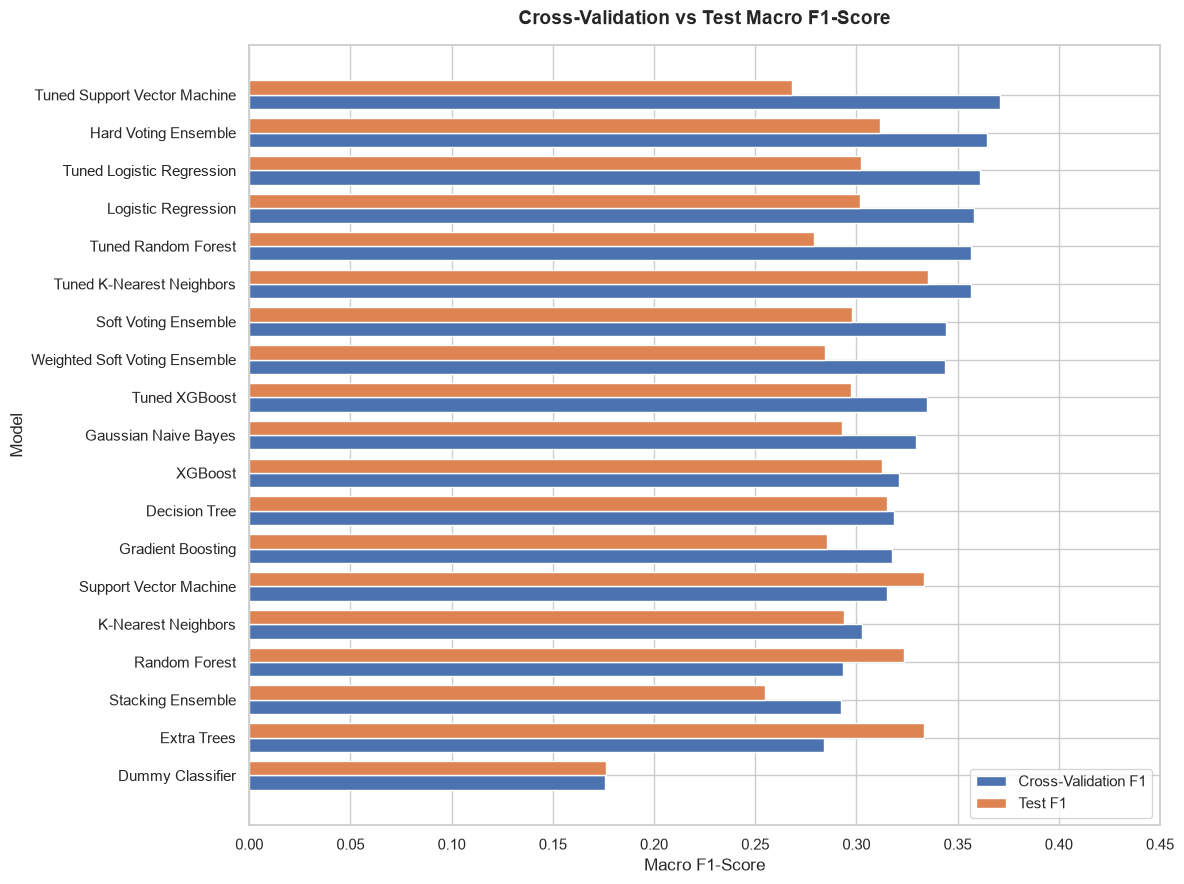

In [6]:
# Visualizing cross-validation and test Macro F1-scores

plot_data = generalization_comparison.sort_values(
    "F1_Macro_CV",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 9))

y_positions = np.arange(len(plot_data))
bar_height = 0.38

ax.barh(
    y_positions - bar_height / 2,
    plot_data["F1_Macro_CV"],
    height=bar_height,
    label="Cross-Validation F1"
)

ax.barh(
    y_positions + bar_height / 2,
    plot_data["F1_Macro_Test"],
    height=bar_height,
    label="Test F1"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Model"])

ax.set_xlabel("Macro F1-Score")
ax.set_ylabel("Model")
ax.set_title(
    "Cross-Validation vs Test Macro F1-Score",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.legend()
ax.set_xlim(0, 0.45)

plt.tight_layout()

plt.savefig(
    figures_dir / "model_generalization_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 5. Investigating Class-Specific Performance

In [7]:
# Generating class-specific evaluation for Tuned SVM

selected_model_name = "tuned_svm"

y_pred_selected = test_predictions[selected_model_name]

class_names = label_encoder.classes_

# Calculating precision, recall, F1-score, and support

class_report = classification_report(
    y_test,
    y_pred_selected,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Organizing class-specific metrics

class_performance = pd.DataFrame(
    class_report
).T

class_performance = class_performance.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

class_performance.index.name = "Severity"

print("Tuned SVM - Class-Specific Performance:")

display(class_performance.round(4))

Tuned SVM - Class-Specific Performance:


,precision,recall,f1-score,support
Severity,,,,
Critical,0.3250,0.3939,0.3562,66.0000
Minor,0.2857,0.3056,0.2953,72.0000
Moderate,0.1860,0.1290,0.1524,62.0000


#### Observations on Class-Specific Performance

- **Critical defects** achieved the highest recall (**39.39%**) and F1-score (**0.3562**), although most Critical cases remained undetected.
- **Minor defects** recorded a recall of **30.56%**, indicating limited identification of low-severity defects.
- **Moderate defects** performed worst, with only **12.90% recall** and an F1-score of **0.1524**, highlighting substantial classification difficulty.

##### 5.1 Visualizing the Confusion Matrix

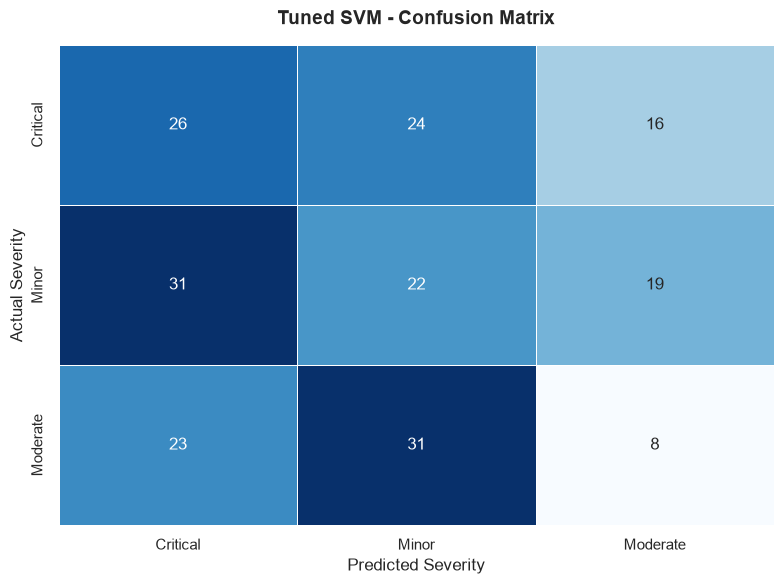

Confusion Matrix:


,Critical,Minor,Moderate
Critical,26,24,16
Minor,31,22,19
Moderate,23,31,8


In [8]:
# Calculating the confusion matrix for Tuned SVM

cm = confusion_matrix(
    y_test,
    y_pred_selected,
    labels=np.arange(len(class_names))
)

# Visualizing class-level prediction outcomes

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    cbar=False,
    ax=ax
)

ax.set_title(
    "Tuned SVM - Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Severity")
ax.set_ylabel("Actual Severity")

plt.tight_layout()

plt.savefig(
    figures_dir / "tuned_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix:")
display(
    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )
)

#### Observations on the Confusion Matrix

- The model correctly classified only **56 of 200 defects (28.00%)**, indicating weak overall classification performance.
- Of the **66 actual Critical defects**, only **26 were correctly identified**, while 40 were misclassified as Minor or Moderate.
- **Moderate defects** showed the greatest classification difficulty, with only **8 of 62 correctly identified** and 31 incorrectly classified as Minor.

#### 6. Investigating Critical Defect Detection

In [9]:
# Evaluating Critical defect detection outcomes

critical_actual = (
    np.asarray(y_test) == critical_class
)

critical_predicted = (
    np.asarray(y_pred_selected) == critical_class
)

# Calculating Critical-class detection outcomes

critical_tp = np.sum(critical_actual & critical_predicted)
critical_fn = np.sum(critical_actual & ~critical_predicted)
critical_fp = np.sum(~critical_actual & critical_predicted)
critical_tn = np.sum(~critical_actual & ~critical_predicted)

# Calculating Critical-class performance metrics

critical_precision = (
    critical_tp / (critical_tp + critical_fp)
    if (critical_tp + critical_fp) > 0 else 0
)

critical_recall = (
    critical_tp / (critical_tp + critical_fn)
    if (critical_tp + critical_fn) > 0 else 0
)

critical_miss_rate = (
    critical_fn / (critical_tp + critical_fn)
    if (critical_tp + critical_fn) > 0 else 0
)

# Organizing Critical defect detection results

critical_detection_results = pd.DataFrame({
    "Metric": [
        "True Positives",
        "False Negatives",
        "False Positives",
        "True Negatives",
        "Critical Precision",
        "Critical Recall",
        "Critical Miss Rate"
    ],
    "Value": [
        critical_tp,
        critical_fn,
        critical_fp,
        critical_tn,
        critical_precision,
        critical_recall,
        critical_miss_rate
    ]
})

print("Tuned SVM - Critical Defect Detection Analysis:")

display(critical_detection_results.round(4))

Tuned SVM - Critical Defect Detection Analysis:


,Metric,Value
0,True Positives,26.0000
1,False Negatives,40.0000
2,False Positives,54.0000
3,True Negatives,80.0000
4,Critical Precision,0.3250
5,Critical Recall,0.3939
6,Critical Miss Rate,0.6061


#### Observations on Critical Defect Detection

- The model correctly identified **26 of 66 Critical defects**, achieving a Critical Recall of **39.39%**.
- The **Critical Miss Rate of 60.61%** indicates that 40 severe defects were incorrectly classified as Minor or Moderate.
- Critical Precision reached only **32.50%**, with 54 non-Critical defects incorrectly predicted as Critical.

##### 6.1 Comparing Critical Defect Detection Across Models

In [10]:
# Comparing Critical-class performance across trained models

critical_model_results = []

for model_file, y_pred in test_predictions.items():

    # Converting multiclass labels into Critical vs Non-Critical

    y_true_binary = (
        np.asarray(y_test) == critical_class
    ).astype(int)

    y_pred_binary = (
        np.asarray(y_pred) == critical_class
    ).astype(int)

    # Calculating Critical-class metrics

    critical_model_results.append({
        "Model": model_name_mapping[model_file],
        "Critical_Precision": precision_score(
            y_true_binary, y_pred_binary, zero_division=0
        ),
        "Critical_Recall": recall_score(
            y_true_binary, y_pred_binary, zero_division=0
        ),
        "Critical_F1": f1_score(
            y_true_binary, y_pred_binary, zero_division=0
        ),
        "Critical_Missed": int(
            np.sum((y_true_binary == 1) & (y_pred_binary == 0))
        ),
        "False_Critical_Alerts": int(
            np.sum((y_true_binary == 0) & (y_pred_binary == 1))
        )
    })

# Organizing the comparison

critical_comparison = (
    pd.DataFrame(critical_model_results)
    .sort_values("Critical_Recall", ascending=False)
    .reset_index(drop=True)
)

print("Critical Defect Detection - Model Comparison:")

display(critical_comparison.round(4))

Critical Defect Detection - Model Comparison:


,Model,Critical_Precision,Critical_Recall,Critical_F1,Critical_Missed,False_Critical_Alerts
0,K-Nearest Neighbors,0.3267,0.5000,0.3952,33,68
1,Hard Voting Ensemble,0.3836,0.4242,0.4029,38,45
2,Logistic Regression,0.3662,0.3939,0.3796,40,45
3,Tuned Logistic Regression,0.3662,0.3939,0.3796,40,45
4,Tuned Support Vector Machine,0.3250,0.3939,0.3562,40,54
5,Tuned K-Nearest Neighbors,0.3824,0.3939,0.3881,40,42
6,Weighted Soft Voting Ensemble,0.3378,0.3788,0.3571,41,49
7,Support Vector Machine,0.4444,0.3636,0.4000,42,30
8,Random Forest,0.3333,0.3636,0.3478,42,48
9,Gaussian Naive Bayes,0.3077,0.3636,0.3333,42,54


#### Observations on Critical Defect Detection

- **K-Nearest Neighbors** achieved the highest Critical Recall (**50.00%**), identifying 33 of 66 Critical defects but generating 68 false Critical alerts.
- **Hard Voting Ensemble** achieved the highest Critical F1-score (**0.4029**), with **42.42% recall** and 45 false Critical alerts.
- **Support Vector Machine** achieved the highest Critical Precision (**44.44%**), although its recall remained limited at **36.36%**.

##### 6.2 Visualizing Critical Defect Detection Performance

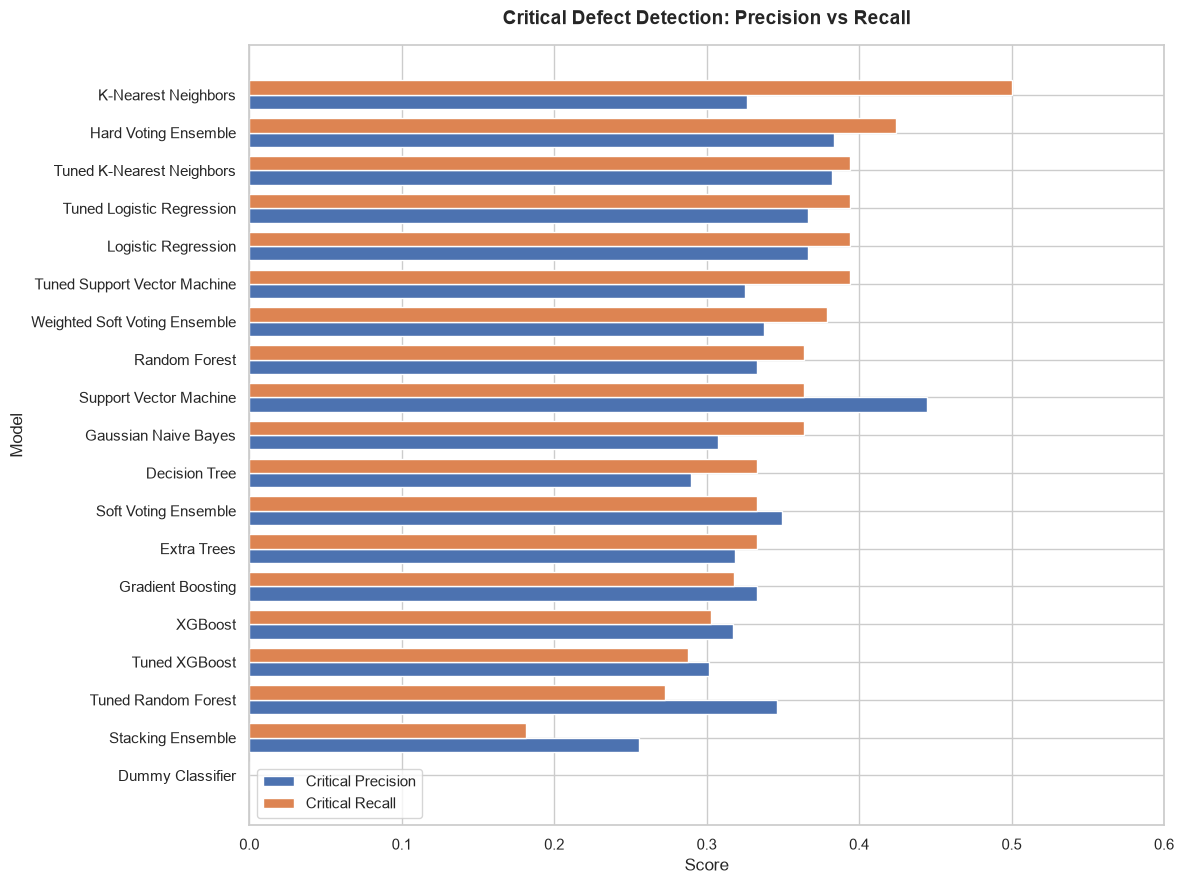

In [11]:
# Comparing Critical Precision and Recall across models

plot_data = critical_comparison.sort_values(
    "Critical_Recall",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 9))

y_positions = np.arange(len(plot_data))
bar_height = 0.38

ax.barh(
    y_positions - bar_height / 2,
    plot_data["Critical_Precision"],
    height=bar_height,
    label="Critical Precision"
)

ax.barh(
    y_positions + bar_height / 2,
    plot_data["Critical_Recall"],
    height=bar_height,
    label="Critical Recall"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Model"])

ax.set_xlabel("Score")
ax.set_ylabel("Model")

ax.set_title(
    "Critical Defect Detection: Precision vs Recall",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlim(0, 0.60)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "critical_precision_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 7. Saving Model Evaluation Results

In [12]:
# Saving held-out test performance results

test_results.to_csv(
    processed_dir / "test_model_comparison.csv",
    index=False
)

# Saving cross-validation and test generalization results

generalization_comparison.to_csv(
    processed_dir / "model_generalization_comparison.csv",
    index=False
)

# Saving Critical defect detection results

critical_comparison.to_csv(
    processed_dir / "critical_defect_comparison.csv",
    index=False
)

# Verifying saved evaluation files

evaluation_files = [
    "test_model_comparison.csv",
    "model_generalization_comparison.csv",
    "critical_defect_comparison.csv"
]

print("Model Evaluation Results:")

for filename in evaluation_files:

    file_path = processed_dir / filename

    print(
        f"{filename}: "
        f"{'Saved Successfully' if file_path.exists() else 'Not Found'}"
    )

print("\nEvaluation Summary:")
print(f"Models Evaluated: {len(test_results)}")
print(f"Test Observations: {len(y_test)}")
print(f"Severity Classes: {len(label_encoder.classes_)}")

Model Evaluation Results:
test_model_comparison.csv: Saved Successfully
model_generalization_comparison.csv: Saved Successfully
critical_defect_comparison.csv: Saved Successfully

Evaluation Summary:
Models Evaluated: 19
Test Observations: 200
Severity Classes: 3


## 8. Model Evaluation Summary

The evaluation assessed 19 classification model configurations on an independent test dataset containing 200 manufacturing defects across three severity classes: Critical, Minor, and Moderate.

### Key Findings

- **Tuned K-Nearest Neighbors** achieved the highest test Macro F1-score of **0.3354**, while the Dummy Classifier recorded the highest overall accuracy of **36.00%**.
- **Tuned Support Vector Machine**, selected through cross-validation, achieved a test Macro F1-score of **0.2679**, compared with **0.3710** during cross-validation, indicating a substantial generalization gap.
- The selected Tuned SVM correctly identified only **26 of 66 Critical defects**, resulting in a **Critical Miss Rate of 60.61%**.
- **Hard Voting Ensemble** achieved the highest Critical F1-score of **0.4029**, while the original K-Nearest Neighbors achieved the highest Critical Recall of **50.00%**.
- The results demonstrate limited predictive reliability across all three severity classes, with particularly weak identification of Moderate defects.

### Evaluation Conclusion

The findings indicate that the available defect characteristics provide insufficient predictive performance for reliable severity classification using the evaluated models. Although some configurations demonstrated modest improvements in individual metrics, none achieved performance suitable for operational quality assurance decisions.

Further investigation into feature importance and model behavior is required to understand the factors influencing predictions and the limitations of the available dataset.